# 03 — VAD Trigger | Calibration → Freeze → Test

**Mục tiêu:** kiểm tra bộ kích hoạt năng lượng trên PCM16 16 kHz, không chạy DSP/AI hay voting. Quy trình: **Quality Gate FROZEN → VAD Calibration → chọn MAV/consecutive → Freeze → Held-out Test**.

Firmware tham chiếu: chunk **256 mẫu**, MAV nguyên với điều kiện **`MAV > threshold`**, warm-up **100 chunk**, ring **1 giây**, capture **5 giây**. `Manual Check` không đi qua VAD; VAD chỉ hoạt động trong `MONITOR_LISTENING`. **64 ms** là thời gian xác nhận bốn chunk, *không phải* độ trễ đo được so với onset âm học có nhãn.

## 0. Chuẩn bị dữ liệu

Tại thư mục `03_VAD_Trigger`, sau khi hoàn tất `02_Quality_Check` và giữ `final_quality_gate.json`:

```powershell
py -3.11 .\test_vad_utils.py
py -3.11 .\Simulate_VAD_Trigger.py plan
py -3.11 .\Simulate_VAD_Trigger.py calibrate
```

`plan` chỉ kiểm tra manifest/headers. `calibrate` chỉ đọc **Calibration**; **không dùng Test để chọn ngưỡng**. Nếu đã có artifact của lần chạy cũ, cần sao lưu `results/` trước khi lập plan lại.

In [1]:
from pathlib import Path
import sys, subprocess, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_experiment_dir():
    start = Path.cwd().resolve()
    relative = Path('Experiments_Benchmarking/Patient_Node/Final_V1_Validation/03_VAD_Trigger')
    candidates = [start, start/'03_VAD_Trigger', start/relative]
    for parent in start.parents:
        candidates.extend([parent/'03_VAD_Trigger', parent/relative])
    checked = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in checked:
            continue
        checked.add(candidate)
        if (candidate/'vad_utils.py').is_file() and (candidate/'Simulate_VAD_Trigger.py').is_file():
            return candidate
    raise FileNotFoundError(
        'Không tìm thấy 03_VAD_Trigger từ working directory: ' + str(start)
    )

HERE = find_experiment_dir()
sys.path.insert(0, str(HERE))
from vad_utils import VadConfig, simulate, freeze, load_frozen, sha256

MANIFEST=HERE/'results'/'vad_source_manifest.csv'
CAL=HERE/'results'/'calibration_source_metrics.csv'
CAL_NPZ=HERE/'results'/'calibration_chunk_mav.npz'
FINAL=HERE/'results'/'final_vad_trigger.json'
TEST=HERE/'results'/'test_source_metrics.csv'
TEST_NPZ=HERE/'results'/'test_chunk_mav.npz'
TEST_EVENTS=HERE/'results'/'test_trigger_events.csv'
assert MANIFEST.exists() and CAL.exists() and CAL_NPZ.exists(), 'Hãy chạy plan + calibrate trước'
manifest=pd.read_csv(MANIFEST)
cal=pd.read_csv(CAL)
assert not (set(manifest.loc[manifest.vad_split.eq('calibration'),'source_group']) &
            set(manifest.loc[manifest.vad_split.eq('test'),'source_group'])), 'SOURCE LEAKAGE!'
assert (manifest.source_kind.eq('environment_master') & manifest.source_group.ne('keyfan_old_01')).sum() == 33, 'Sai 33 Environment master'
assert (manifest.loc[manifest.source_kind.eq('environment_master') & manifest.source_group.ne('keyfan_old_01') & manifest.vad_split.eq('test'),'source_group'].nunique()) == 3
assert manifest.loc[manifest.source_group.eq('silence_old_01'),'vad_split'].eq('calibration').all()
print('Calibration WAV:',len(cal),'| Test WAV header only:',manifest.vad_split.eq('test').sum())
print('Calibration nguồn:',cal.source_group.nunique())
display(manifest.groupby(['vad_split','source_kind','subtype']).agg(wav_count=('file_name','count'),sources=('source_group','nunique')).reset_index())
# KHÔNG tải test_chunk_mav.npz trong các mục 0–4.
chunk=np.load(CAL_NPZ,allow_pickle=False)

Calibration WAV: 176 | Test WAV header only: 19
Calibration nguồn: 104


,vad_split,source_kind,subtype,wav_count,sources
0,calibration,environment_master,clap,6,6
1,calibration,environment_master,fan,5,5
2,calibration,environment_master,fan_keyboard,1,1
3,calibration,environment_master,knock,4,4
4,calibration,environment_master,podcast,6,6
5,calibration,environment_master,room_noise,5,5
6,calibration,environment_master,speech,4,4
7,calibration,playback,playback_asthma,72,36
8,calibration,playback,playback_non_asthma_disease,72,36
9,calibration,quality_check_asset,silence,1,1


## 1. Baseline `75/4` trên Calibration

- **Playback:** giả định monitor được bật trước khi phát và warm-up đã xong; 1 giây đầu của WAV dùng lấp ring. Đây là giả định mô phỏng, **không phải onset âm học thật**.
- **Environment:** mô phỏng warm-up và capture liên tục; `capture_complete=False` chỉ có nghĩa WAV kết thúc trước khi đủ 5 giây.
- Đếm **WAV có ít nhất một trigger**, không xem các *take* từ một nguồn như các nguồn độc lập.

In [2]:
def analyse(cfg, frame=cal, arrays=chunk):
    rows=[]; events=[]
    for x in frame.itertuples(index=False):
        mav=arrays[str(x.chunk_key)+'_mav']
        lengths=arrays[str(x.chunk_key)+'_len']
        ev=simulate(mav,lengths,cfg,playback_prearmed=bool(x.playback_prearmed))
        rows.append({'source_group':x.source_group,'source_kind':x.source_kind,
                     'subtype':x.subtype,'file_name':x.file_name,
                     'duration_s':x.duration_s,'trigger_count':len(ev),
                     'activated':int(bool(ev)),
                     'complete_count':sum(e['capture_complete'] for e in ev),
                     'activation_per_min':len(ev)*60/float(x.duration_s)})
        events.extend([{'source_group':x.source_group,'file_name':x.file_name,
                        'subtype':x.subtype,**event} for event in ev])
    return pd.DataFrame(rows),pd.DataFrame(events)

baseline=VadConfig(threshold=75,consecutive=4)
base_sources,base_events=analyse(baseline)
display(base_sources.groupby(['source_kind','subtype']).agg(
    wav_count=('file_name','count'),activated_files=('activated','sum'),
    event_count=('trigger_count','sum'),mean_activations_per_min=('activation_per_min','mean')
).reset_index())
print('Playback activated (file):',base_sources.loc[base_sources.source_kind.eq('playback'),'activated'].sum(),
      '/',base_sources.source_kind.eq('playback').sum())
print('Silence:',base_sources.loc[base_sources.subtype.eq('silence'),['trigger_count','duration_s']].to_dict('records'))
display(base_events.head(10))

,source_kind,subtype,wav_count,activated_files,event_count,mean_activations_per_min
0,environment_master,clap,6,6,50,8.333333
1,environment_master,fan,5,5,50,10.000000
2,environment_master,fan_keyboard,1,1,50,10.000000
3,environment_master,knock,4,4,22,5.500000
4,environment_master,podcast,6,6,99,9.966667
5,environment_master,room_noise,5,5,37,7.400000
6,environment_master,speech,4,4,38,9.500000
7,playback,playback_asthma,72,70,70,8.128684
8,playback,playback_non_asthma_disease,72,49,49,5.702704
9,quality_check_asset,silence,1,1,15,3.000000


Playback activated (file): 119 / 144
Silence: [{'trigger_count': 15, 'duration_s': 300.0}]


,source_group,file_name,subtype,candidate_onset_s,confirmed_s,confirmation_delay_ms,recovered_samples,recovered_ms,confirm_mav,capture_complete,complete_within_file,capture_end_s
0,PB_Asthma_AST_001__P10AsthmaIU_50,AST_001__P10AsthmaIU_50__take01.wav,playback_asthma,1.824,1.888,64.0,1024,64.0,120,True,True,6.824
1,PB_Asthma_AST_001__P10AsthmaIU_50,AST_001__P10AsthmaIU_50__take02.wav,playback_asthma,1.696,1.760,64.0,1024,64.0,156,True,True,6.696
2,PB_Asthma_AST_002__P12WheezingRS_56,AST_002__P12WheezingRS_56__take01.wav,playback_asthma,1.120,1.184,64.0,1024,64.0,200,True,True,6.120
3,PB_Asthma_AST_002__P12WheezingRS_56,AST_002__P12WheezingRS_56__take02.wav,playback_asthma,1.168,1.232,64.0,1024,64.0,416,True,True,6.168
4,PB_Asthma_AST_004__P14WheezingRS_68,AST_004__P14WheezingRS_68__take01.wav,playback_asthma,1.216,1.280,64.0,1024,64.0,206,True,True,6.216
5,PB_Asthma_AST_004__P14WheezingRS_68,AST_004__P14WheezingRS_68__take02.wav,playback_asthma,1.232,1.296,64.0,1024,64.0,203,True,True,6.232
6,PB_Asthma_AST_005__P2AsthmaRL_7,AST_005__P2AsthmaRL_7__take01.wav,playback_asthma,1.120,1.184,64.0,1024,64.0,177,True,True,6.120
7,PB_Asthma_AST_005__P2AsthmaRL_7,AST_005__P2AsthmaRL_7__take02.wav,playback_asthma,1.168,1.232,64.0,1024,64.0,1179,True,True,6.168
8,PB_Asthma_AST_006__P20WheezingRS_100,AST_006__P20WheezingRS_100__take01.wav,playback_asthma,1.088,1.152,64.0,1024,64.0,106,True,True,6.088
9,PB_Asthma_AST_006__P20WheezingRS_100,AST_006__P20WheezingRS_100__take02.wav,playback_asthma,1.200,1.264,64.0,1024,64.0,163,True,True,6.200


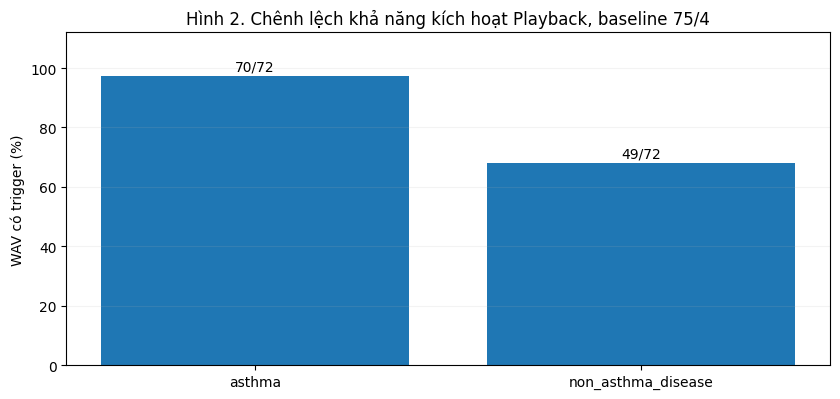

Thống kê số take kích hoạt trong mỗi nhóm nguồn Playback:


,subtype,hits,source_groups
0,playback_asthma,0,1
1,playback_asthma,2,35
2,playback_non_asthma_disease,0,11
3,playback_non_asthma_disease,1,1
4,playback_non_asthma_disease,2,24


In [3]:
# Hình 2 — Playback: so sánh tỷ lệ phát hiện theo nhãn và hai take/nguồn
pb_rows = base_sources.loc[base_sources.source_kind.eq('playback')].copy()
fig, ax = plt.subplots(figsize=(8.5, 4.1))
pb_by_class = pb_rows.groupby('subtype')['activated'].agg(['sum','count']).reset_index()
ax.bar(pb_by_class.subtype.str.replace('playback_', '', regex=False),
       100 * pb_by_class['sum'] / pb_by_class['count'])
for j, r in pb_by_class.iterrows():
    ax.text(j, 100 * r['sum'] / r['count'] + 2, f"{int(r['sum'])}/{int(r['count'])}", ha='center')
ax.set(ylim=(0, 112), ylabel='WAV có trigger (%)',
       title='Hình 2. Chênh lệch khả năng kích hoạt Playback, baseline 75/4')
ax.grid(axis='y', alpha=.15)
plt.tight_layout(); plt.show()

pb_groups = pb_rows.groupby(['subtype','source_group']).agg(hits=('activated','sum'),
                                                           takes=('activated','size')).reset_index()
print('Thống kê số take kích hoạt trong mỗi nhóm nguồn Playback:')
display(pb_groups.groupby(['subtype','hits']).size().rename('source_groups').reset_index())

## 2. So sánh 9 cặp MAV/consecutive

Khảo sát `{50, 75, 100} × {3, 4, 5}` với các tham số firmware còn lại giữ cố định. Cân bằng tỷ lệ **Playback kích hoạt** và số trigger trên **một bản ghi Silence cũ 5 phút**; đây **không phải** chỉ số false-positive tổng quát.

In [4]:
from itertools import product
summary=[]
for threshold,consecutive in product([50,75,100],[3,4,5]):
    cfg=VadConfig(threshold=threshold,consecutive=consecutive)
    r,_=analyse(cfg)
    pb=r.loc[r.source_kind.eq('playback')]
    sil=r.loc[r.subtype.eq('silence')]
    env=r.loc[r.source_kind.eq('environment_master')]
    pb_group=pb.groupby('source_group')['activated'].max()
    summary.append({
        'threshold':threshold,'consecutive':consecutive,
        'pb_activated_wav':f"{int(pb.activated.sum())}/{len(pb)}",
        'pb_activated_groups':f"{int(pb_group.sum())}/{len(pb_group)}",
        'silence_triggers':int(sil.trigger_count.sum()),
        'silence_triggers_per_min':float(sil.activation_per_min.mean()),
        'env_mean_activations_per_min':float(env.activation_per_min.mean()),
        'env_activated_wav':int(env.activated.sum()),
    })
sweep=pd.DataFrame(summary).sort_values(['threshold','consecutive'])
display(sweep)
output=HERE/'results'/'candidate_vad_sweep.csv'
if output.exists(): print('Đã tồn tại; không ghi đè:',output)
else: sweep.to_csv(output,index=False,encoding='utf-8-sig')

,threshold,consecutive,pb_activated_wav,pb_activated_groups,silence_triggers,silence_triggers_per_min,env_mean_activations_per_min,env_activated_wav
0,50,3,132/144,66/72,39,7.8,9.193548,31
1,50,4,129/144,65/72,35,7.0,9.129032,31
2,50,5,128/144,64/72,32,6.4,8.929032,31
3,75,3,125/144,63/72,18,3.6,8.735484,31
4,75,4,119/144,60/72,15,3.0,8.606452,31
5,75,5,118/144,59/72,11,2.2,8.412903,31
6,100,3,121/144,61/72,7,1.4,8.380645,31
7,100,4,118/144,59/72,5,1.0,8.116129,30
8,100,5,115/144,58/72,4,0.8,7.948387,29


Đã tồn tại; không ghi đè: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\03_VAD_Trigger\results\candidate_vad_sweep.csv


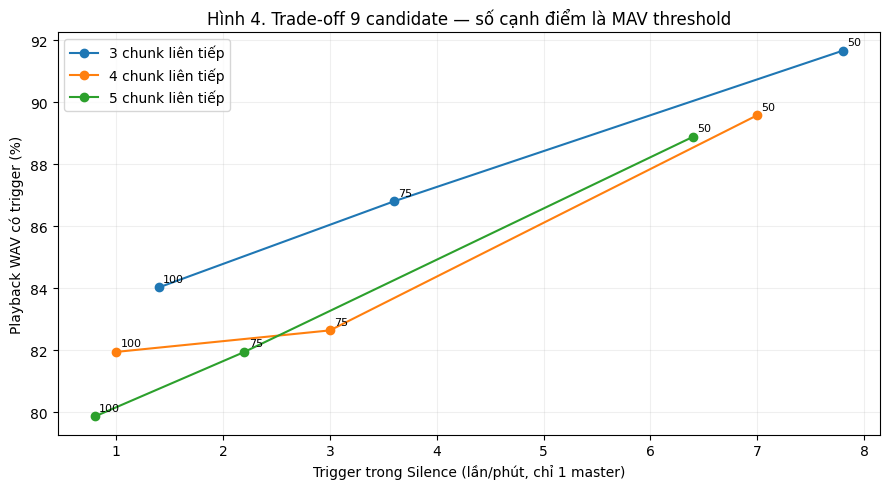

In [5]:
# Hình 4 — Mối đánh đổi kích hoạt Playback và trigger trên Silence
check = sweep.copy()
check['pb_hits'] = check['pb_activated_wav'].str.split('/').str[0].astype(int)
check['pb_total'] = check['pb_activated_wav'].str.split('/').str[1].astype(int)
check['pb_rate'] = 100 * check['pb_hits'] / check['pb_total']
fig, ax = plt.subplots(figsize=(9, 5))
for cons, group in check.groupby('consecutive'):
    ax.plot(group.silence_triggers_per_min, group.pb_rate, marker='o',
            label=f'{cons} chunk liên tiếp')
    for r in group.itertuples():
        ax.annotate(str(r.threshold), (r.silence_triggers_per_min, r.pb_rate),
                    xytext=(3, 4), textcoords='offset points', fontsize=8)
ax.set(xlabel='Trigger trong Silence (lần/phút, chỉ 1 master)',
       ylabel='Playback WAV có trigger (%)',
       title='Hình 4. Trade-off 9 candidate — số cạnh điểm là MAV threshold')
ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.show()

## 3. Đối chiếu ngưỡng sát baseline và lựa chọn

Các mức `80/4`, `85/4`, `90/4`, `100/4` được kiểm tra thêm để tìm WAV bị dịch **candidate onset** quá 1 giây so với `75/4`. Đây chỉ là độ dịch *giữa hai cấu hình*, không phải độ trễ đối với onset bệnh lý. Ưu tiên bắt đầu thu Playback sớm trong trạng thái Monitor, đồng thời ghi nhận kích hoạt do nguồn môi trường.

In [6]:
# Chỉ sử dụng Calibration; xuất bảng so sánh thu gọn, tránh audit từng WAV.
comparison_rows = []
ref_onset = (base_events.loc[base_events.subtype.str.startswith('playback_'),
                             ['file_name', 'candidate_onset_s']]
             .drop_duplicates('file_name').rename(columns={'candidate_onset_s': 'ref_onset'}))
for threshold in (75, 80, 85, 90, 100):
    r, events = analyse(VadConfig(threshold=threshold, consecutive=4))
    pb = r.loc[r.source_kind.eq('playback')]
    current = (events.loc[events.subtype.str.startswith('playback_'),
                          ['file_name', 'candidate_onset_s']]
               .drop_duplicates('file_name').rename(columns={'candidate_onset_s': 'new_onset'}))
    paired = ref_onset.merge(current, on='file_name', validate='one_to_one')
    delay_ms = (paired.new_onset - paired.ref_onset) * 1000
    comparison_rows.append({
        'MAV / consecutive': f'{threshold}/4',
        'Playback trigger': f'{int(pb.activated.sum())}/{len(pb)}',
        'Asthma trigger': f"{int(pb.loc[pb.subtype.eq('playback_asthma'), 'activated'].sum())}/72",
        'Silence cũ (trigger/300s)': int(r.loc[r.subtype.eq('silence'), 'trigger_count'].sum()),
        'Onset muộn >1s (WAV)': int((delay_ms > 1000).sum()),
        'Onset muộn nhất (ms)': round(float(delay_ms.max()), 1) if len(delay_ms) else 0,
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison)

FINAL_VAD_THRESHOLD, FINAL_CONSECUTIVE = 75, 4
selected_cfg = VadConfig(threshold=FINAL_VAD_THRESHOLD, consecutive=FINAL_CONSECUTIVE)
SELECTION_NOTE = (
    'Chọn MAV >75 trong 4 chunk liên tiếp bằng Calibration: Playback 119/144 WAV, '
    'Asthma 70/72; Silence cũ 15 trigger/300s. Tăng ngưỡng có thể giảm trigger '
    'nền nhưng làm một số Playback xuất hiện candidate onset muộn hàng giây. '
    'Đối chứng Silence mới là phân tích bổ sung, không phải held-out Test. '
    'VAD dựa trên năng lượng, không nhận dạng nội dung hô hấp. '
    'Không dùng Test để lựa chọn cấu hình.'
)
print('Đề xuất:', selected_cfg)

,MAV / consecutive,Playback trigger,Asthma trigger,Silence cũ (trigger/300s),Onset muộn >1s (WAV),Onset muộn nhất (ms)
0,75/4,119/144,70/72,15,0,0.0
1,80/4,118/144,70/72,11,4,4672.0
2,85/4,118/144,70/72,8,5,4672.0
3,90/4,118/144,70/72,6,8,4672.0
4,100/4,118/144,70/72,5,14,5392.0


Đề xuất: VadConfig(threshold=75, consecutive=4, chunk_samples=256, sample_rate=16000, pre_roll_samples=16000, capture_samples=80000, warmup_chunks=100)


## 4. Freeze cấu hình trước Test

Chỉ đặt `FREEZE_NOW=True` sau khi đã duyệt bảng Calibration. Nếu `final_vad_trigger.json` đã tồn tại, **chỉ đọc và đối chiếu**; không ghi đè hoặc thay đổi ngưỡng. Khi muốn làm thí nghiệm mới, sao lưu `results/` trước.

In [7]:
FREEZE_NOW = False  # Đổi thành True chỉ khi chưa có JSON và đã duyệt Calibration.
if FINAL.exists():
    frozen_cfg, frozen_metadata = load_frozen(FINAL, MANIFEST, CAL, CAL_NPZ)
    if frozen_cfg != selected_cfg:
        raise ValueError(f'FROZEN hiện tại {frozen_cfg} khác lựa chọn {selected_cfg}; không được ghi đè.')
    print('Đã có FROZEN hợp lệ; giữ nguyên:', FINAL)
elif FREEZE_NOW:
    freeze(FINAL, selected_cfg, MANIFEST, CAL, CAL_NPZ, SELECTION_NOTE)
    frozen_cfg, frozen_metadata = load_frozen(FINAL, MANIFEST, CAL, CAL_NPZ)
    print('Đã tạo FROZEN:', FINAL)
else:
    print('Chưa Freeze. Duyệt Calibration, sau đó bật FREEZE_NOW=True.')

Đã có FROZEN hợp lệ; giữ nguyên: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\03_VAD_Trigger\results\final_vad_trigger.json


## 5. Held-out Test — chỉ sau Freeze

Chỉ bật `RUN_HELDOUT_TEST=True` khi đã xác nhận JSON FROZEN. Nếu Test cache đã có, cell kiểm tra sự phù hợp của file theo manifest và **tái mô phỏng events bằng đúng cấu hình FROZEN** để phát hiện dùng nhầm output; không dùng Test để điều chỉnh `75/4`.

In [8]:
RUN_HELDOUT_TEST = False  # Đổi True sau khi FROZEN.
if RUN_HELDOUT_TEST:
    cfg, frozen_metadata = load_frozen(FINAL, MANIFEST, CAL, CAL_NPZ)
    test_paths = (TEST, TEST_NPZ, TEST_EVENTS)
    if any(p.exists() for p in test_paths) and not all(p.exists() for p in test_paths):
        raise FileExistsError('Test cache chưa đầy đủ; sao lưu và kiểm tra trước khi chạy lại.')
    if not all(p.exists() for p in test_paths):
        subprocess.run([sys.executable, str(HERE/'Simulate_VAD_Trigger.py'), 'test'],
                       check=True, cwd=str(HERE))
    heldout = pd.read_csv(TEST)
    expected = manifest.loc[manifest.vad_split.eq('test'), ['source_group', 'file_path']]
    got = heldout[['source_group', 'file_path']]
    assert sorted(map(tuple, expected.to_numpy())) == sorted(map(tuple, got.to_numpy())),         'Test cache không khớp nguồn trong manifest VAD.'
    with np.load(TEST_NPZ, allow_pickle=False) as test_arrays:
        source_test, simulated_events = analyse(cfg, heldout, test_arrays)
    stored_events = pd.read_csv(TEST_EVENTS)
    assert len(simulated_events) == len(stored_events), 'Số trigger trong cache không khớp config FROZEN.'
    if len(simulated_events):
        simulation = simulated_events.copy()
        simulation['event_no'] = simulation.groupby(['source_group', 'file_name']).cumcount() + 1
        keys = ['source_group', 'file_name', 'event_no']
        actual = stored_events.set_index(keys).sort_index()
        regenerated = simulation.set_index(keys).sort_index()
        assert actual.index.equals(regenerated.index), 'Event index trong cache khác simulation.'
        for field in ('candidate_onset_s', 'confirmed_s'):
            assert np.allclose(actual[field].astype(float), regenerated[field].astype(float), atol=1e-6),                 f'Cache không khớp {field} của config FROZEN.'
    display(source_test.groupby(['source_kind','subtype']).agg(
        wav=('file_name','count'), activated=('activated','sum'),
        triggers=('trigger_count','sum'), capture_complete=('complete_count','sum')
    ).reset_index())
    print('Đã xác minh Test trên cấu hình FROZEN:', cfg)
else:
    print('Chưa mở Test. Chỉ bật sau khi FROZEN.')

Chưa mở Test. Chỉ bật sau khi FROZEN.


## 6. Đối chứng bổ sung (không dùng chọn lại ngưỡng)

So sánh **Silence cũ**, **Silence mới** và **Room noise 02** theo chuỗi `VAD 75/4 → capture 5s → Quality Gate đã FROZEN`. Đây là kiểm tra *diagnostic*, không thuộc Held-out Test. Cần giữ `extra_validation/vad_silence_session_01.wav` để chạy lại hai cell sau; nếu không có file, có thể bỏ qua phần bổ sung này.

In [9]:
# 7.1 — Đọc ba WAV; nạp Quality Gate FROZEN từ 02; tuyệt đối không đọc Test VAD.
SILENCE_NEW_PATH = None  # Hoặc Path(r'D:\NCKH_2026\...\vad_silence_session_01.wav')
import wave

qc_dir = (HERE.parent/'02_Quality_Check').resolve()
if str(qc_dir) not in sys.path:
    sys.path.insert(0,str(qc_dir))
from quality_utils import QualityThresholds, classify_audio, file_sha256
qc_final = qc_dir/'results'/'final_quality_gate.json'
qc_manifest = qc_dir/'results'/'quality_window_manifest.csv'
qc_calibration = qc_dir/'results'/'calibration_metrics.csv'
quality_meta=json.loads(qc_final.read_text(encoding='utf-8'))
assert quality_meta.get('status')=='FROZEN'
assert quality_meta.get('manifest_sha256')==file_sha256(qc_manifest)
assert quality_meta.get('calibration_metrics_sha256')==file_sha256(qc_calibration)
qc_params_external=QualityThresholds(**quality_meta['thresholds'])
qc_params_external.validate()


def calibration_source_path(session_id):
    matches=cal.loc[(cal.session_id==session_id)&
                    (cal.vad_split=='calibration'),'file_path'].unique()
    if len(matches)!=1:
        raise ValueError(f'Không tìm được đúng 1 Calibration WAV cho {session_id}: {list(matches)}')
    return Path(matches[0]).resolve()


def get_new_silence(path_override):
    expected='vad_silence_session_01.wav'
    if path_override is not None:
        p=Path(path_override).expanduser().resolve()
        if not p.is_file() or p.name.casefold()!=expected:
            raise FileNotFoundError(f'Chưa tìm được đúng {expected}: {p}')
        return p
    roots=[HERE/'extra_validation',HERE.parent/'extra_validation',
           HERE.parent/'02_Quality_Check'/'extra_validation',
           HERE.parent.parent.parent.parent/'AI_Training_Model'/'Dataset_TuThu_v_Kaggle'/'TuThu'/'Record_Env']
    candidates=sorted({p.resolve() for root in roots if root.is_dir()
                       for p in root.rglob(expected)})
    if len(candidates)!=1:
        raise FileNotFoundError(f'Cần chỉ rõ SILENCE_NEW_PATH, tìm thấy {len(candidates)} file {expected}')
    return candidates[0]

vad_three_paths={
    'Silence cũ':calibration_source_path('silence_old_01'),
    'Silence mới':get_new_silence(SILENCE_NEW_PATH),
    'Room noise 02':calibration_source_path('room_noise_session_02'),
}
assert vad_three_paths['Silence mới'] not in {Path(x).resolve() for x in manifest.file_path},     'Silence mới đang ở manifest: kiểm tra nguy cơ dùng sai split!'

def read_pcm_source(path):
    with wave.open(str(path),'rb') as wf:
        spec=(wf.getnchannels(),wf.getsampwidth(),wf.getframerate(),wf.getcomptype())
        if spec!=(1,2,16000,'NONE'):
            raise ValueError(f'Không đúng PCM16 mono 16000 Hz: {path}, {spec}')
        return np.frombuffer(wf.readframes(wf.getnframes()),dtype='<i2').copy()

from vad_utils import pcm16_chunk_mav
print('VAD đang ở trạng thái:', 'FROZEN' if FINAL.exists() else 'CHƯA FREEZE')
print('Quality Gate FROZEN:', qc_params_external)
for name,path in vad_three_paths.items():print(name,':',path)

VAD đang ở trạng thái: FROZEN
Quality Gate FROZEN: QualityThresholds(min_rms=20.0, min_active_ratio=0.01, max_clipped_ratio=0.01, clip_level=32000, active_block_threshold=20, block_size=256)
Silence cũ : D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\Dataset_TuThu_v_Kaggle\TuThu\Record_Env\Silence\silence_5min.wav
Silence mới : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\03_VAD_Trigger\extra_validation\vad_silence_session_01.wav
Room noise 02 : D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\Dataset_TuThu_v_Kaggle\TuThu\Record_Env\Room_Noise\room_noise_session_02.wav


TỔNG HỢP VAD:


,source,duration_s,mean_mav,median_mav,max_mav,triggers,triggers_per_min,complete_in_wav
0,Silence cũ,300.0,48.8213,44.0,355,15,3.0,14
1,Silence mới,300.0,4.5771,4.0,110,0,0.0,0
2,Room noise 02,60.0,116.3931,67.0,2854,9,9.0,8


TRẠNG THÁI QC SAU TRIGGER:


quality_state,AUDIO_OK,WAV_END_BEFORE_5S
source,,
Room noise 02,8,1
Silence cũ,14,1


,source,trigger_no,onset_s,confirm_s,capture_complete,quality_state,rms,active_ratio,clipped_ratio
15,Room noise 02,1,2.592,2.656,True,AUDIO_OK,364.782071,1.000000,0.0
16,Room noise 02,2,8.592,8.656,True,AUDIO_OK,413.928905,1.000000,0.0
17,Room noise 02,3,14.800,14.864,True,AUDIO_OK,234.414203,1.000000,0.0
18,Room noise 02,4,21.136,21.200,True,AUDIO_OK,109.656612,1.000000,0.0
19,Room noise 02,5,27.296,27.360,True,AUDIO_OK,84.832121,1.000000,0.0
20,Room noise 02,6,35.440,35.504,True,AUDIO_OK,110.417000,0.990415,0.0
21,Room noise 02,7,41.488,41.552,True,AUDIO_OK,103.455580,0.996805,0.0
22,Room noise 02,8,48.320,48.384,True,AUDIO_OK,85.674196,0.980831,0.0
23,Room noise 02,9,55.248,55.312,False,WAV_END_BEFORE_5S,NaN,NaN,NaN
0,Silence cũ,1,9.456,9.520,True,AUDIO_OK,123.841037,1.000000,0.0


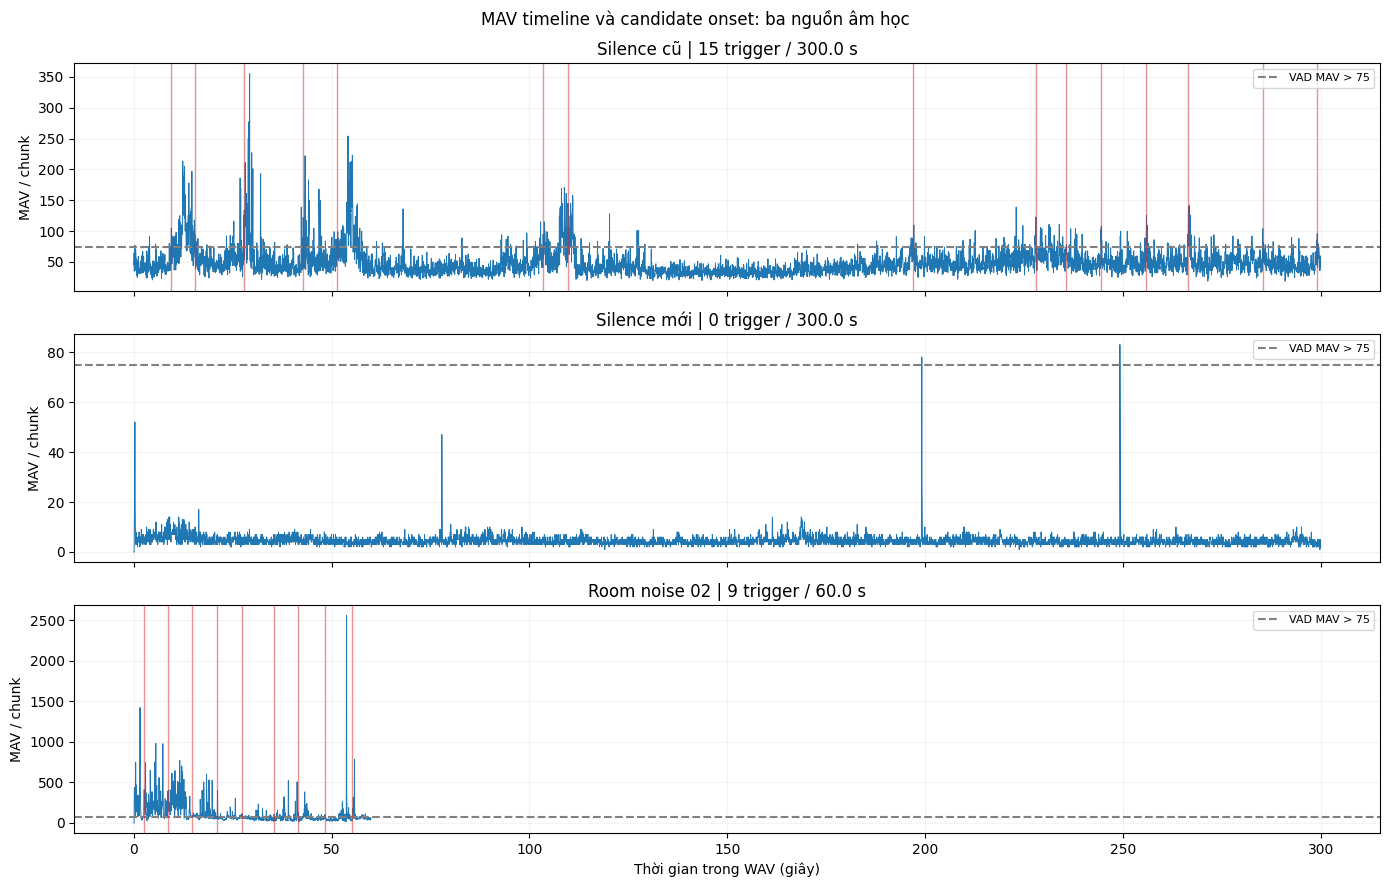

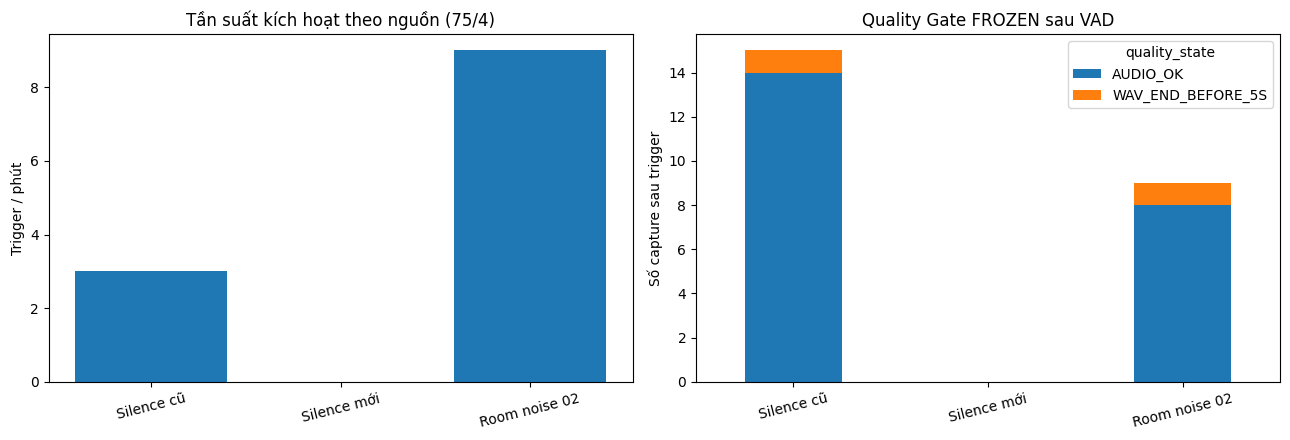

Đã lưu bảng vào: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\03_VAD_Trigger\results\supplemental_validation


In [10]:
# 7.2 — VAD 75/4 → Capture 5 s → Quality Gate FROZEN trên ba nguồn.
# Đối chiếu DIAGNOSTIC, không sử dụng để điều chỉnh ngưỡng rồi gọi là Test độc lập.
v_diag_cfg=VadConfig(threshold=75,consecutive=4)
v_diag_source_rows=[]
v_diag_event_rows=[]
v_diag_chunk={}
v_diag_pcm={}
for label,path in vad_three_paths.items():
    pcm=read_pcm_source(path)
    v_diag_pcm[label]=pcm
    mav,lengths=pcm16_chunk_mav(pcm)
    v_diag_chunk[label]=mav
    events=simulate(mav,lengths,v_diag_cfg,playback_prearmed=False)
    v_diag_source_rows.append({'source':label,'duration_s':len(pcm)/16000,
         'mean_mav':float(mav.mean()),'median_mav':float(np.median(mav)),
         'max_mav':int(mav.max()),'triggers':len(events),
         'triggers_per_min':len(events)*60/(len(pcm)/16000),
         'complete_in_wav':sum(bool(e['capture_complete']) for e in events)})
    for k,event in enumerate(events,1):
        onset=int(round(float(event['candidate_onset_s'])*16000))
        complete=bool(event['capture_complete']) and onset+80000<=len(pcm)
        row={'source':label,'trigger_no':k,'onset_s':float(event['candidate_onset_s']),
             'confirm_s':float(event['confirmed_s']),
             'capture_complete':complete,'quality_state':'WAV_END_BEFORE_5S',
             'rms':np.nan,'active_ratio':np.nan,'clipped_ratio':np.nan}
        if complete:
            state,met=classify_audio(pcm[onset:onset+80000],qc_params_external)
            row.update(quality_state=state,rms=met['rms'],
                       active_ratio=met['active_ratio'],clipped_ratio=met['clipped_ratio'])
        v_diag_event_rows.append(row)

v_diag_sources=pd.DataFrame(v_diag_source_rows)
v_diag_events=pd.DataFrame(v_diag_event_rows,columns=[
    'source','trigger_no','onset_s','confirm_s','capture_complete',
    'quality_state','rms','active_ratio','clipped_ratio'])
print('TỔNG HỢP VAD:')
display(v_diag_sources.round(4))
print('TRẠNG THÁI QC SAU TRIGGER:')
if not v_diag_events.empty:
    display(pd.crosstab(v_diag_events.source,v_diag_events.quality_state))
    display(v_diag_events.sort_values(['source','onset_s']).head(24))
else:
    print('Không có trigger nào trên ba session với ngưỡng 75/4.')

outputfolder=HERE/'results'/'supplemental_validation'
outputfolder.mkdir(parents=True,exist_ok=True)
v_diag_sources.to_csv(outputfolder/'three_session_vad_sources.csv',index=False,encoding='utf-8-sig')
v_diag_events.to_csv(outputfolder/'three_session_vad_qc_events.csv',index=False,encoding='utf-8-sig')

fig,axes=plt.subplots(3,1,figsize=(14,9),sharex=True)
for ax,(label,path) in zip(axes,vad_three_paths.items()):
    wav=v_diag_pcm[label]
    mav=v_diag_chunk[label]
    tt=(np.arange(len(mav))+.5)*256/16000
    ax.plot(tt[::3],mav[::3],lw=.7)
    ax.axhline(v_diag_cfg.threshold,ls='--',color='gray',label='VAD MAV > 75')
    ev=v_diag_events.loc[v_diag_events.source==label]
    for t in ev.onset_s:
        ax.axvline(t,color='tab:red',alpha=.5,lw=1)
    ax.set(ylabel='MAV / chunk',title=f'{label} | {len(ev)} trigger / {len(wav)/16000:.1f} s')
    ax.legend(loc='upper right',fontsize=8);ax.grid(alpha=.15)
axes[-1].set_xlabel('Thời gian trong WAV (giây)')
plt.suptitle('MAV timeline và candidate onset: ba nguồn âm học')
plt.tight_layout();plt.show()

fig,axs=plt.subplots(1,2,figsize=(13,4.5))
axs[0].bar(v_diag_sources.source,v_diag_sources.triggers_per_min)
axs[0].set(ylabel='Trigger / phút',title='Tần suất kích hoạt theo nguồn (75/4)')
axs[0].tick_params(axis='x',rotation=14)
if not v_diag_events.empty:
    st=(pd.crosstab(v_diag_events.source,v_diag_events.quality_state)
        .reindex(v_diag_sources.source,fill_value=0))
    st.plot(kind='bar',stacked=True,ax=axs[1])
    axs[1].set(xlabel='',ylabel='Số capture sau trigger',title='Quality Gate FROZEN sau VAD')
    axs[1].tick_params(axis='x',rotation=14)
else:
    axs[1].text(.5,.5,'Không trigger',ha='center',va='center',transform=axs[1].transAxes)
plt.tight_layout();plt.show()

print('Đã lưu bảng vào:',outputfolder)

## 7. Kết luận — VAD V1

| Tham số được khóa | Giá trị |
|---|---:|
| MAV threshold (so sánh `>`) | **75** |
| Consecutive chunk | **4** |
| Chunk / sample rate | **256 mẫu / 16 kHz** |
| Xác nhận trigger | **64 ms** |
| Warm-up | **100 chunk** |
| Ring / capture | **1 s / 5 s** |

| Kết quả | Calibration | Held-out Test lịch sử |
|---|---:|---:|
| Playback kích hoạt | **119/144 WAV** | **14/16 WAV** |
| Asthma Playback kích hoạt | **70/72** | **8/8** |
| Non-Asthma Playback kích hoạt | **49/72** | **6/8** |

**Đối chứng ngoài sweep:** Silence mới **0 trigger/300s**, Silence cũ **15 trigger/300s**, Room noise 02 **9 trigger/60s**. Với các capture đầy đủ từ Silence cũ và Room noise 02, Quality Gate đều chấp nhận (`14/14` và `8/8`). Điều này cho thấy **VAD theo năng lượng không phân biệt được nguồn âm hô hấp với tiếng môi trường**, và Quality Gate không thay thế bộ phân loại nội dung.

**Phạm vi:** các tỷ lệ trên là kết quả mô phỏng trên WAV (hai take/nguồn), không đo recall theo onset âm học và không phải kết quả hệ thống end-to-end. `capture_complete=False` chỉ phản ánh WAV hết trước 5 giây. VAD chưa kiểm chứng parity với firmware, DSP/AI và logic 3-vote trên ESP32-S3; không dùng Test đã xem để hiệu chỉnh lại tham số.